# Convex Optimizaiton

## Dependencies

In [15]:
import numpy as np
import matplotlib.pyplot as plt
# from scipy.optimize import linprog
from cvxopt import matrix, solvers
from itertools import combinations

## Data

In [16]:
A = np.array([[1, 1], [-1, 2], [2, -1], [-1, 0], [0, -1]], dtype=float)
b = np.array([5, 4, 6, 0, 0], dtype=float)

m, d = A.shape
nA = np.zeros((m))

print(f"Number of constraints: {m}")
print(f"Number of variables: {d}")

Number of constraints: 5
Number of variables: 2


## Creating augmented constraints

In [17]:
for k in range(m):
    nA[k] = np.linalg.norm(A[k, :])

AA = np.vstack([np.hstack([A, nA.reshape(-1, 1)]), np.array([0, 0, -1])])
bb = np.hstack([b, 0])

print("AA = ", AA)
print("bb = ", bb)

AA =  [[ 1.          1.          1.41421356]
 [-1.          2.          2.23606798]
 [ 2.         -1.          2.23606798]
 [-1.          0.          1.        ]
 [ 0.         -1.          1.        ]
 [ 0.          0.         -1.        ]]
bb =  [5. 4. 6. 0. 0. 0.]


## Linear programming definition

In [18]:
f0 = -np.hstack([np.zeros(d), 1])

# No equality constraints in this example
C, d = None, None

## Solver

In [19]:
cc = matrix(f0)
G = matrix(AA)
h = matrix(bb)

solution = solvers.lp(cc, G, h, C, d)

     pcost       dcost       gap    pres   dres   k/t
 0: -1.4085e+00 -1.7714e+01  1e+01  3e-01  8e+00  1e+00
 1: -1.2592e+00 -3.0115e+00  5e-01  4e-02  9e-01  2e-01
 2: -1.3489e+00 -1.4439e+00  2e-02  2e-03  5e-02  8e-03
 3: -1.3532e+00 -1.3549e+00  4e-04  3e-05  8e-04  1e-04
 4: -1.3533e+00 -1.3533e+00  4e-06  3e-07  8e-06  1e-06
 5: -1.3533e+00 -1.3533e+00  4e-08  3e-09  8e-08  1e-08
Optimal solution found.


## Extracting results

In [20]:
x0 = solution['x']
f0 = solution['primal objective']
y0 = solution['z']

print("Status:", solution['status'])
print("Optimal value:", solution['primal objective'])
print("Optimal variables:", list(solution['x']))
print("Dual variables:", list(solution['z']))

Status: optimal
Optimal value: -1.3533261479111807
Optimal variables: [1.7327815769140005, 1.3533261392415352, 1.3533261479111807]
Dual variables: [0.15036960349342546, 0.1503695717096065, 1.8734975760732303e-09, 2.4183319633660644e-08, 0.45110873369164567, 6.406947805101365e-10]


## Plotting results

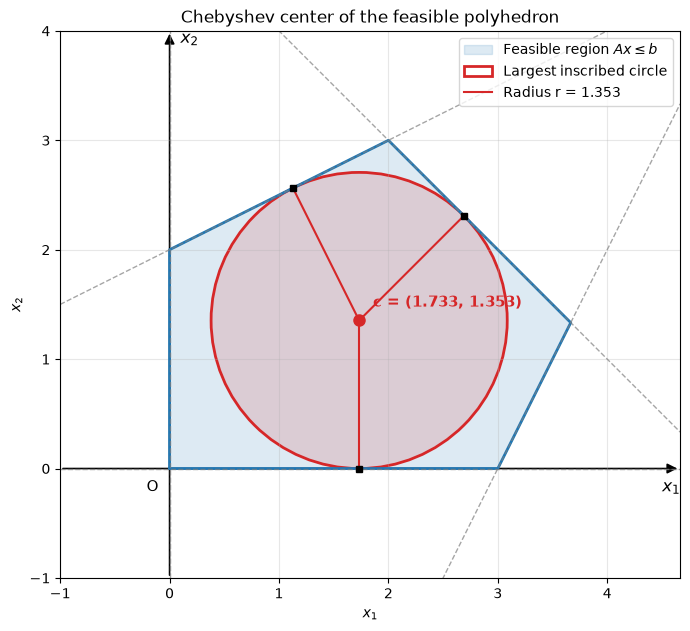

In [21]:
def feasible_polygon(A: np.ndarray, b: np.ndarray, tol: float = 1e-9) -> np.ndarray:
    """Compute the vertices of the 2D polygon {x : A x <= b}.

    Every pair of constraint lines is intersected, intersection points that
    violate any constraint are discarded, and the remaining vertices are
    sorted counter-clockwise around their centroid.

    Args:
        A: Constraint matrix of shape (m, 2).
        b: Right-hand side vector of shape (m,).
        tol: Numerical tolerance used for feasibility and singularity checks.

    Returns:
        Array of shape (k, 2) with the polygon vertices ordered counter-clockwise.
    """
    vertices = []
    for i, j in combinations(range(A.shape[0]), 2):
        M = A[[i, j], :]
        if abs(np.linalg.det(M)) < tol:
            continue  # Parallel lines: no unique intersection
        p = np.linalg.solve(M, b[[i, j]])
        if np.all(A @ p <= b + tol):
            vertices.append(p)
    vertices = np.unique(np.round(vertices, 10), axis=0)
    center = vertices.mean(axis=0)
    angles = np.arctan2(vertices[:, 1] - center[1], vertices[:, 0] - center[0])
    return vertices[np.argsort(angles)]


# --- Optimal solution: Chebyshev center and radius ---
x_opt = np.array(x0).flatten()
c_opt, r_opt = x_opt[:2], x_opt[2]

# --- Geometry ---
polygon = feasible_polygon(A, b)
active = np.where(np.abs(A @ c_opt + r_opt * nA - b) < 1e-6)[0]  # Constraints touching the circle

pad = 1.0
x_min, y_min = np.minimum(polygon.min(axis=0), 0) - pad  # Always keep the origin in view
x_max, y_max = np.maximum(polygon.max(axis=0), 0) + pad
xs = np.linspace(x_min, x_max, 400)

fig, ax = plt.subplots(figsize=(8, 8))

# Coordinate axes (x1 = 0 and x2 = 0) with arrow heads
axis_style = dict(arrowstyle="-|>", color="black", lw=1.2, mutation_scale=15)
ax.annotate("", xy=(x_max, 0), xytext=(x_min, 0), arrowprops=axis_style, zorder=1)
ax.annotate("", xy=(0, y_max), xytext=(0, y_min), arrowprops=axis_style, zorder=1)
ax.text(x_max, -0.1, "$x_1$", ha="right", va="top", fontsize=12)
ax.text(0.1, y_max, "$x_2$", ha="left", va="top", fontsize=12)
ax.text(-0.1, -0.1, "O", ha="right", va="top", fontsize=11)

# Feasible region
ax.fill(polygon[:, 0], polygon[:, 1], color="tab:blue", alpha=0.15, label="Feasible region $Ax \\leq b$")
ax.plot(*np.vstack([polygon, polygon[0]]).T, color="tab:blue", lw=2)

# Constraint lines a_k^T x = b_k
for k in range(m):
    a1, a2 = A[k]
    style = dict(color="gray", lw=1, ls="--", alpha=0.7)
    if abs(a2) > 1e-12:
        ax.plot(xs, (b[k] - a1 * xs) / a2, **style)
    else:
        ax.axvline(b[k] / a1, **style)

# Inscribed circle
circle = plt.Circle(c_opt, r_opt, color="tab:red", fill=True, alpha=0.15)
ax.add_patch(circle)
ax.add_patch(plt.Circle(c_opt, r_opt, color="tab:red", fill=False, lw=2, label="Largest inscribed circle"))

# Center
ax.plot(*c_opt, "o", color="tab:red", ms=8, zorder=5)
ax.annotate(f"c = ({c_opt[0]:.3f}, {c_opt[1]:.3f})", c_opt, xytext=(10, 10),
            textcoords="offset points", fontsize=11, color="tab:red", fontweight="bold")

# Radius segments to the tangency points on the active constraints
for idx, k in enumerate(active):
    tangent = c_opt + r_opt * A[k] / nA[k]
    ax.plot(*np.vstack([c_opt, tangent]).T, color="tab:red", lw=1.5, ls="-",
            label=f"Radius r = {r_opt:.3f}" if idx == 0 else None)
    ax.plot(*tangent, "s", color="black", ms=5, zorder=5)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Chebyshev center of the feasible polyhedron")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()

## A